In [ ]:
# Crime Pattern Mining and Crime Category Prediction

## Using Data Warehousing and Data Mining

### Objective
#Analyze historical district-wise crime data using
#Data Warehousing, OLAP and Data Mining techniques.

#The machine learning model uses the crime pattern of a
#district in one year to predict the dominant crime category
#in the following year.

### Dataset
#District-wise Crimes Committed under IPC (2001–2012)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Load dataset
file_path = "/content/01_District_wise_crimes_committed_IPC_2001_2012.csv"

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (9017, 33)


,STATE/UT,DISTRICT,YEAR,MURDER,ATTEMPT TO MURDER,CULPABLE HOMICIDE NOT AMOUNTING TO MURDER,RAPE,CUSTODIAL RAPE,OTHER RAPE,KIDNAPPING & ABDUCTION,...,ARSON,HURT/GREVIOUS HURT,DOWRY DEATHS,ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY,INSULT TO MODESTY OF WOMEN,CRUELTY BY HUSBAND OR HIS RELATIVES,IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES,CAUSING DEATH BY NEGLIGENCE,OTHER IPC CRIMES,TOTAL IPC CRIMES
0,ANDHRA PRADESH,ADILABAD,2001,101,60,17,50,0,50,46,...,30,1131,16,149,34,175,0,181,1518,4154
1,ANDHRA PRADESH,ANANTAPUR,2001,151,125,1,23,0,23,53,...,69,1543,7,118,24,154,0,270,754,4125
2,ANDHRA PRADESH,CHITTOOR,2001,101,57,2,27,0,27,59,...,38,2088,14,112,83,186,0,404,1262,5818
3,ANDHRA PRADESH,CUDDAPAH,2001,80,53,1,20,0,20,25,...,23,795,17,126,38,57,0,233,1181,3140
4,ANDHRA PRADESH,EAST GODAVARI,2001,82,67,1,23,0,23,49,...,41,1244,12,109,58,247,0,431,2313,6507


In [ ]:
# Standardize column names
df.columns = df.columns.str.strip().str.upper()

# Standardize categorical columns
df["STATE/UT"] = df["STATE/UT"].astype(str).str.strip().str.upper()
df["DISTRICT"] = df["DISTRICT"].astype(str).str.strip().str.upper()

# Remove duplicate rows
df = df.drop_duplicates()

# Remove aggregate TOTAL rows
df = df[df["DISTRICT"] != "TOTAL"].copy()

# Convert crime columns to numeric
id_columns = ["STATE/UT", "DISTRICT", "YEAR"]

crime_columns = [
    col for col in df.columns
    if col not in id_columns
]

for col in crime_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Fill remaining numeric missing values
df[crime_columns] = df[crime_columns].fillna(0)

print("Cleaned Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
display(df.head())

Cleaned Dataset Shape: (8609, 33)
Missing Values: 0


,STATE/UT,DISTRICT,YEAR,MURDER,ATTEMPT TO MURDER,CULPABLE HOMICIDE NOT AMOUNTING TO MURDER,RAPE,CUSTODIAL RAPE,OTHER RAPE,KIDNAPPING & ABDUCTION,...,ARSON,HURT/GREVIOUS HURT,DOWRY DEATHS,ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY,INSULT TO MODESTY OF WOMEN,CRUELTY BY HUSBAND OR HIS RELATIVES,IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES,CAUSING DEATH BY NEGLIGENCE,OTHER IPC CRIMES,TOTAL IPC CRIMES
0,ANDHRA PRADESH,ADILABAD,2001,101,60,17,50,0,50,46,...,30,1131,16,149,34,175,0,181,1518,4154
1,ANDHRA PRADESH,ANANTAPUR,2001,151,125,1,23,0,23,53,...,69,1543,7,118,24,154,0,270,754,4125
2,ANDHRA PRADESH,CHITTOOR,2001,101,57,2,27,0,27,59,...,38,2088,14,112,83,186,0,404,1262,5818
3,ANDHRA PRADESH,CUDDAPAH,2001,80,53,1,20,0,20,25,...,23,795,17,126,38,57,0,233,1181,3140
4,ANDHRA PRADESH,EAST GODAVARI,2001,82,67,1,23,0,23,49,...,41,1244,12,109,58,247,0,431,2313,6507


In [ ]:
# Standardize column names
df.columns = df.columns.str.strip().str.upper()

# Standardize categorical columns
df["STATE/UT"] = df["STATE/UT"].astype(str).str.strip().str.upper()
df["DISTRICT"] = df["DISTRICT"].astype(str).str.strip().str.upper()

# Remove duplicate rows
df = df.drop_duplicates()

# Remove aggregate TOTAL rows
df = df[df["DISTRICT"] != "TOTAL"].copy()

# Convert crime columns to numeric
id_columns = ["STATE/UT", "DISTRICT", "YEAR"]

crime_columns = [
    col for col in df.columns
    if col not in id_columns
]

for col in crime_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Fill remaining numeric missing values
df[crime_columns] = df[crime_columns].fillna(0)

print("Cleaned Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
display(df.head())

Cleaned Dataset Shape: (8609, 33)
Missing Values: 0


,STATE/UT,DISTRICT,YEAR,MURDER,ATTEMPT TO MURDER,CULPABLE HOMICIDE NOT AMOUNTING TO MURDER,RAPE,CUSTODIAL RAPE,OTHER RAPE,KIDNAPPING & ABDUCTION,...,ARSON,HURT/GREVIOUS HURT,DOWRY DEATHS,ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY,INSULT TO MODESTY OF WOMEN,CRUELTY BY HUSBAND OR HIS RELATIVES,IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES,CAUSING DEATH BY NEGLIGENCE,OTHER IPC CRIMES,TOTAL IPC CRIMES
0,ANDHRA PRADESH,ADILABAD,2001,101,60,17,50,0,50,46,...,30,1131,16,149,34,175,0,181,1518,4154
1,ANDHRA PRADESH,ANANTAPUR,2001,151,125,1,23,0,23,53,...,69,1543,7,118,24,154,0,270,754,4125
2,ANDHRA PRADESH,CHITTOOR,2001,101,57,2,27,0,27,59,...,38,2088,14,112,83,186,0,404,1262,5818
3,ANDHRA PRADESH,CUDDAPAH,2001,80,53,1,20,0,20,25,...,23,795,17,126,38,57,0,233,1181,3140
4,ANDHRA PRADESH,EAST GODAVARI,2001,82,67,1,23,0,23,49,...,41,1244,12,109,58,247,0,431,2313,6507


Years: 2001 - 2012
States/UTs: 35
Districts: 807


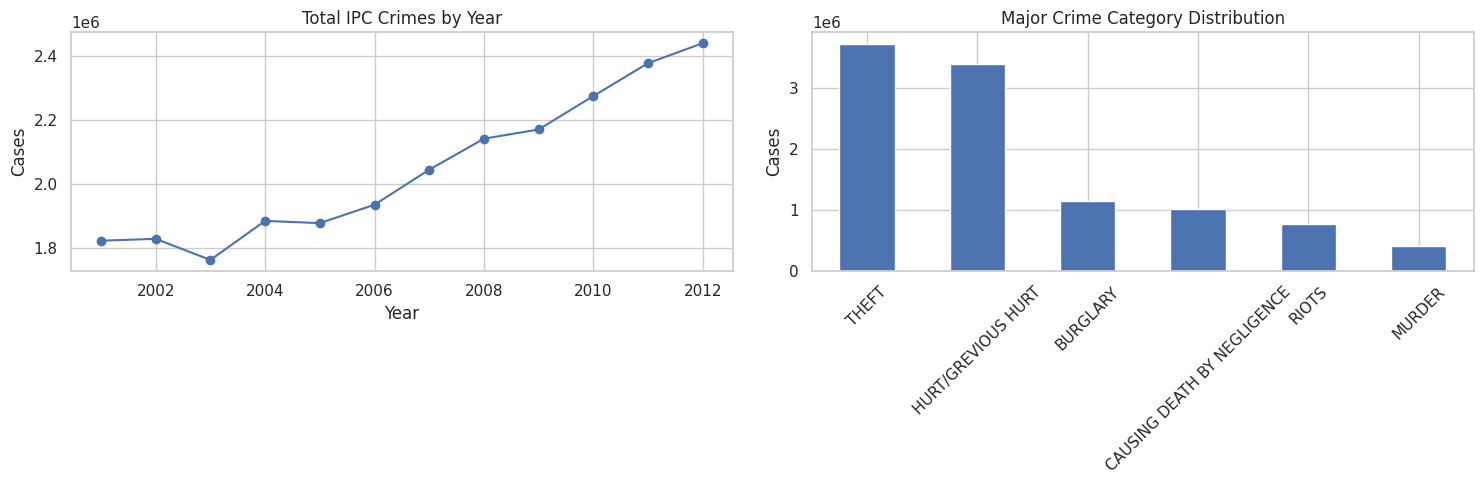

In [ ]:
print("Years:", df["YEAR"].min(), "-", df["YEAR"].max())
print("States/UTs:", df["STATE/UT"].nunique())
print("Districts:", df["DISTRICT"].nunique())

# Crime columns
prediction_categories = [
    "THEFT",
    "HURT/GREVIOUS HURT",
    "CAUSING DEATH BY NEGLIGENCE",
    "RIOTS",
    "BURGLARY",
    "MURDER"
]

# Yearly crime
yearly_crime = (
    df.groupby("YEAR")["TOTAL IPC CRIMES"]
    .sum()
)

# Top crime categories
crime_totals = (
    df[prediction_categories]
    .sum()
    .sort_values(ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

yearly_crime.plot(
    ax=axes[0],
    marker="o"
)
axes[0].set_title("Total IPC Crimes by Year")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Cases")

crime_totals.plot(
    kind="bar",
    ax=axes[1]
)
axes[1].set_title("Major Crime Category Distribution")
axes[1].set_ylabel("Cases")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# DIMENSION: DATE
dim_date = (
    df[["YEAR"]]
    .drop_duplicates()
    .sort_values("YEAR")
    .reset_index(drop=True)
)

dim_date.insert(
    0,
    "DATE_ID",
    range(1, len(dim_date) + 1)
)

# DIMENSION: LOCATION
dim_location = (
    df[["STATE/UT", "DISTRICT"]]
    .drop_duplicates()
    .sort_values(["STATE/UT", "DISTRICT"])
    .reset_index(drop=True)
)

dim_location.insert(
    0,
    "LOCATION_ID",
    range(1, len(dim_location) + 1)
)

# DIMENSION: CRIME
dim_crime = pd.DataFrame({
    "CRIME_ID": range(1, len(prediction_categories) + 1),
    "CRIME_TYPE": prediction_categories
})

# FACT TABLE
fact_crime = df[
    ["STATE/UT", "DISTRICT", "YEAR"] +
    prediction_categories
].copy()

fact_crime = fact_crime.merge(
    dim_date,
    on="YEAR",
    how="left"
)

fact_crime = fact_crime.merge(
    dim_location,
    on=["STATE/UT", "DISTRICT"],
    how="left"
)

print("DIM_DATE:", dim_date.shape)
print("DIM_LOCATION:", dim_location.shape)
print("DIM_CRIME:", dim_crime.shape)
print("FACT_CRIME:", fact_crime.shape)

display(fact_crime.head())

DIM_DATE: (12, 2)
DIM_LOCATION: (828, 3)
DIM_CRIME: (6, 2)
FACT_CRIME: (8609, 11)


,STATE/UT,DISTRICT,YEAR,THEFT,HURT/GREVIOUS HURT,CAUSING DEATH BY NEGLIGENCE,RIOTS,BURGLARY,MURDER,DATE_ID,LOCATION_ID
0,ANDHRA PRADESH,ADILABAD,2001,199,1131,181,78,198,101,1,7
1,ANDHRA PRADESH,ANANTAPUR,2001,366,1543,270,168,191,151,1,8
2,ANDHRA PRADESH,CHITTOOR,2001,723,2088,404,156,237,101,1,9
3,ANDHRA PRADESH,CUDDAPAH,2001,173,795,233,164,98,80,1,10
4,ANDHRA PRADESH,EAST GODAVARI,2001,1021,1244,431,70,437,82,1,12


In [ ]:
# ---------------- ROLL-UP ----------------
state_analysis = (
    df.groupby("STATE/UT")["TOTAL IPC CRIMES"]
    .sum()
    .sort_values(ascending=False)
)

print("ROLL-UP: State-level crime")
display(state_analysis.head(10))


# ---------------- DRILL-DOWN ----------------
top_state = state_analysis.index[0]

district_analysis = (
    df[df["STATE/UT"] == top_state]
    .groupby("DISTRICT")["TOTAL IPC CRIMES"]
    .sum()
    .sort_values(ascending=False)
)

print("\nDRILL-DOWN:", top_state, "→ District")
display(district_analysis.head(10))


# ---------------- SLICE ----------------
slice_data = df[df["YEAR"] == 2010]

print("\nSLICE: Year = 2010")
display(slice_data.head())


# ---------------- DICE ----------------
dice_data = df[
    (df["YEAR"].isin([2009, 2010, 2011, 2012])) &
    (df["STATE/UT"].isin([
        "ANDHRA PRADESH",
        "KARNATAKA",
        "TAMIL NADU"
    ]))
]

print("\nDICE: Selected years + states")
display(dice_data.head())


# ---------------- PIVOT ----------------
pivot = pd.pivot_table(
    df,
    values="TOTAL IPC CRIMES",
    index="STATE/UT",
    columns="YEAR",
    aggfunc="sum"
)

print("\nPIVOT: State × Year")
display(pivot.head(10))

ROLL-UP: State-level crime


,TOTAL IPC CRIMES
STATE/UT,
MADHYA PRADESH,2413770
MAHARASHTRA,2273436
TAMIL NADU,2060176
ANDHRA PRADESH,2018981
UTTAR PRADESH,1858074
RAJASTHAN,1855916
KARNATAKA,1481063
KERALA,1437459
GUJARAT,1385775



DRILL-DOWN: MADHYA PRADESH → District


,TOTAL IPC CRIMES
DISTRICT,
INDORE,204398
BHOPAL,169575
JABALPUR,119446
GWALIOR,111206
UJJAIN,97841
SAGAR,95017
DEWAS,71266
DHAR,63019
SATNA,62648



SLICE: Year = 2010


,STATE/UT,DISTRICT,YEAR,MURDER,ATTEMPT TO MURDER,CULPABLE HOMICIDE NOT AMOUNTING TO MURDER,RAPE,CUSTODIAL RAPE,OTHER RAPE,KIDNAPPING & ABDUCTION,...,ARSON,HURT/GREVIOUS HURT,DOWRY DEATHS,ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY,INSULT TO MODESTY OF WOMEN,CRUELTY BY HUSBAND OR HIS RELATIVES,IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES,CAUSING DEATH BY NEGLIGENCE,OTHER IPC CRIMES,TOTAL IPC CRIMES
6636,ANDHRA PRADESH,ADILABAD,2010,98,90,9,48,0,48,55,...,26,1044,18,133,155,429,0,342,1726,4955
6637,ANDHRA PRADESH,ANANTAPUR,2010,137,101,7,20,0,20,81,...,35,2066,20,132,35,250,0,574,1020,5854
6638,ANDHRA PRADESH,CHITTOOR,2010,100,50,1,44,0,44,85,...,19,827,32,136,121,388,0,552,1977,5218
6639,ANDHRA PRADESH,CUDDAPAH,2010,99,40,5,39,0,39,63,...,37,1385,15,137,45,321,0,484,2089,5694
6640,ANDHRA PRADESH,CYBERABAD,2010,187,84,10,95,0,95,150,...,61,3529,43,157,1257,1191,0,1080,1543,16348



DICE: Selected years + states


,STATE/UT,DISTRICT,YEAR,MURDER,ATTEMPT TO MURDER,CULPABLE HOMICIDE NOT AMOUNTING TO MURDER,RAPE,CUSTODIAL RAPE,OTHER RAPE,KIDNAPPING & ABDUCTION,...,ARSON,HURT/GREVIOUS HURT,DOWRY DEATHS,ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY,INSULT TO MODESTY OF WOMEN,CRUELTY BY HUSBAND OR HIS RELATIVES,IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES,CAUSING DEATH BY NEGLIGENCE,OTHER IPC CRIMES,TOTAL IPC CRIMES
5869,ANDHRA PRADESH,ADILABAD,2009,85,39,11,67,0,67,73,...,35,1254,13,192,163,428,0,333,1762,5312
5870,ANDHRA PRADESH,ANANTAPUR,2009,140,78,4,22,0,22,68,...,22,1049,14,157,13,143,0,649,1814,5181
5871,ANDHRA PRADESH,CHITTOOR,2009,85,68,2,33,0,33,74,...,45,1040,19,120,268,333,0,682,2582,7268
5872,ANDHRA PRADESH,CUDDAPAH,2009,93,44,0,27,0,27,57,...,44,1061,17,165,52,124,0,522,2327,5510
5873,ANDHRA PRADESH,CYBERABAD,2009,186,84,15,82,0,82,168,...,71,3136,46,173,155,991,0,1063,2487,14841



PIVOT: State × Year


YEAR,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012
STATE/UT,,,,,,,,,,,,
A & N ISLANDS,658,608,644,748,682,676,807,882,941,980,793,683
ANDHRA PRADESH,130089,143610,156951,158756,157123,173909,175087,179275,180441,181438,189780,192522
ARUNACHAL PRADESH,2342,2228,2061,2256,2304,2294,2286,2374,2362,2439,2286,2420
ASSAM,36877,36346,38195,40675,42006,43673,45282,53333,55313,61668,66714,77682
BIHAR,88432,94040,92263,108060,97850,100665,109420,122669,122931,127453,135896,146614
CHANDIGARH,3397,3806,2806,2889,3133,3126,3643,3931,3555,3373,3542,3606
CHHATTISGARH,38460,37950,38449,41927,43633,45177,45845,51442,51370,54958,57218,54598
D & N HAVELI,350,349,338,409,434,435,425,401,442,378,372,318
DAMAN & DIU,239,261,269,198,243,288,260,248,276,203,224,239


In [ ]:
df_model = df.copy()

# Find dominant crime in each district/year
df_model["DOMINANT_CRIME"] = (
    df_model[prediction_categories]
    .idxmax(axis=1)
)

# Sort chronologically
df_model = df_model.sort_values(
    ["STATE/UT", "DISTRICT", "YEAR"]
)

# Target = dominant crime of next year
df_model["TARGET_NEXT_YEAR"] = (
    df_model
    .groupby(["STATE/UT", "DISTRICT"])["DOMINANT_CRIME"]
    .shift(-1)
)

df_model["NEXT_YEAR"] = (
    df_model
    .groupby(["STATE/UT", "DISTRICT"])["YEAR"]
    .shift(-1)
)

# Keep only consecutive years
df_model = df_model[
    df_model["NEXT_YEAR"] == df_model["YEAR"] + 1
].copy()

print("ML Dataset Shape:", df_model.shape)

display(
    df_model[
        [
            "STATE/UT",
            "DISTRICT",
            "YEAR",
            "DOMINANT_CRIME",
            "TARGET_NEXT_YEAR"
        ]
    ].head(10)
)

ML Dataset Shape: (7767, 36)


,STATE/UT,DISTRICT,YEAR,DOMINANT_CRIME,TARGET_NEXT_YEAR
689,A & N ISLANDS,ANDAMAN,2001,HURT/GREVIOUS HURT,HURT/GREVIOUS HURT
1407,A & N ISLANDS,ANDAMAN,2002,HURT/GREVIOUS HURT,HURT/GREVIOUS HURT
2136,A & N ISLANDS,ANDAMAN,2003,HURT/GREVIOUS HURT,HURT/GREVIOUS HURT
2865,A & N ISLANDS,ANDAMAN,2004,HURT/GREVIOUS HURT,THEFT
3598,A & N ISLANDS,ANDAMAN,2005,THEFT,THEFT
5836,A & N ISLANDS,ANDAMAN,2008,THEFT,THEFT
6603,A & N ISLANDS,ANDAMAN,2009,THEFT,THEFT
7382,A & N ISLANDS,ANDAMAN,2010,THEFT,BURGLARY
690,A & N ISLANDS,NICOBAR,2001,HURT/GREVIOUS HURT,HURT/GREVIOUS HURT
1408,A & N ISLANDS,NICOBAR,2002,HURT/GREVIOUS HURT,MURDER


In [ ]:
# Features
X = df_model[
    ["STATE/UT", "DISTRICT", "YEAR"] +
    prediction_categories
].copy()

y = df_model["TARGET_NEXT_YEAR"].copy()

# Crime ratios
total_selected = X[prediction_categories].sum(axis=1).replace(0, 1)

for crime in prediction_categories:
    X[f"{crime}_RATIO"] = (
        X[crime] / total_selected
    )

# Encoders
state_encoder = LabelEncoder()
district_encoder = LabelEncoder()
target_encoder = LabelEncoder()

X["STATE_ENCODED"] = state_encoder.fit_transform(
    X["STATE/UT"]
)

X["DISTRICT_ENCODED"] = district_encoder.fit_transform(
    X["DISTRICT"]
)

y_encoded = target_encoder.fit_transform(y)

# Remove text columns
X = X.drop(
    columns=["STATE/UT", "DISTRICT"]
)

print("Features:", X.shape[1])
print("Classes:", target_encoder.classes_)

Features: 15
Classes: ['BURGLARY' 'CAUSING DEATH BY NEGLIGENCE' 'HURT/GREVIOUS HURT' 'MURDER'
 'RIOTS' 'THEFT']


In [ ]:
train_mask = df_model["YEAR"] <= 2008
test_mask = df_model["YEAR"] >= 2009

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y_encoded[train_mask]
y_test = y_encoded[test_mask]

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

print(
    "Training years:",
    sorted(df_model.loc[train_mask, "YEAR"].unique())
)

print(
    "Testing years:",
    sorted(df_model.loc[test_mask, "YEAR"].unique())
)

Training samples: 5561
Testing samples : 2206
Training years: [np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008)]
Testing years: [np.int64(2009), np.int64(2010), np.int64(2011)]


In [ ]:
# Decision Tree
dt_model = DecisionTreeClassifier(
    max_depth=12,
    random_state=42,
    class_weight="balanced"
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)


# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Both models trained successfully!")

Both models trained successfully!


In [ ]:
def evaluate_model(name, y_true, predictions):

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true,
            predictions,
            average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            predictions,
            average="weighted",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_true,
            predictions,
            average="weighted",
            zero_division=0
        )
    }


results = pd.DataFrame([
    evaluate_model(
        "Decision Tree",
        y_test,
        dt_pred
    ),
    evaluate_model(
        "Random Forest",
        y_test,
        rf_pred
    )
])

display(results)

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.747960,0.784868,0.747960,0.761235
1,Random Forest,0.821396,0.826291,0.821396,0.821796


Random Forest Classification Report
                             precision    recall  f1-score   support

                   BURGLARY       0.48      0.32      0.39        34
CAUSING DEATH BY NEGLIGENCE       0.51      0.69      0.59       134
         HURT/GREVIOUS HURT       0.90      0.84      0.87       991
                     MURDER       0.56      0.68      0.61        22
                      RIOTS       0.54      0.36      0.43        53
                      THEFT       0.83      0.86      0.85       972

                   accuracy                           0.82      2206
                  macro avg       0.64      0.63      0.62      2206
               weighted avg       0.83      0.82      0.82      2206



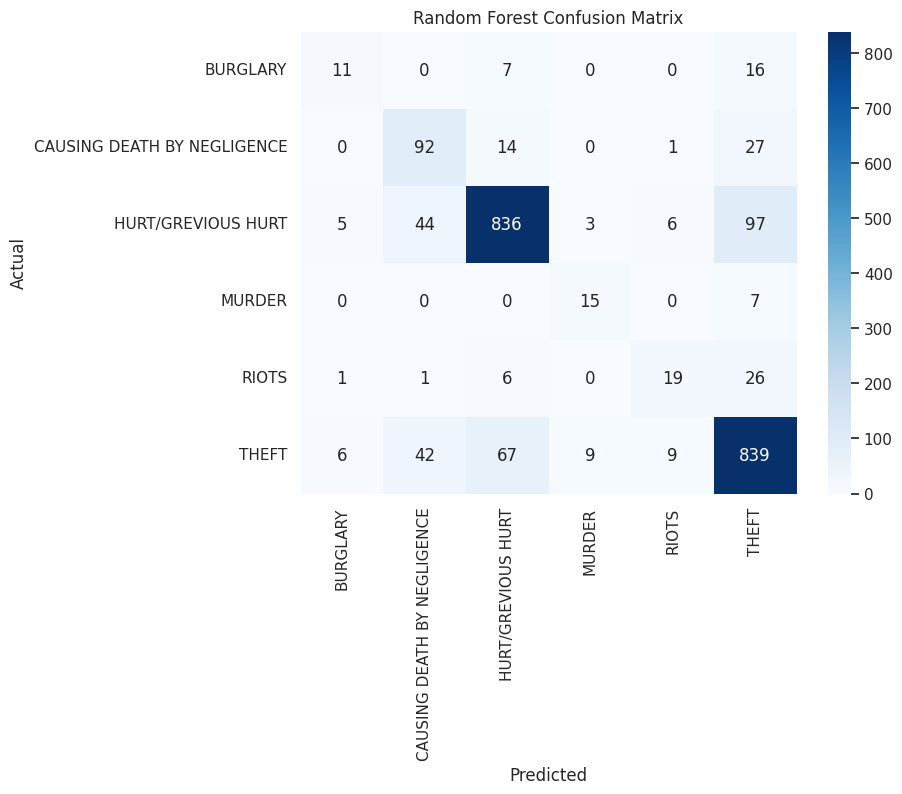

,Feature,Importance
12,MURDER_RATIO,0.121444
10,RIOTS_RATIO,0.112796
11,BURGLARY_RATIO,0.104060
9,CAUSING DEATH BY NEGLIGENCE_RATIO,0.103468
8,HURT/GREVIOUS HURT_RATIO,0.093812
7,THEFT_RATIO,0.085144
1,THEFT,0.065159
2,HURT/GREVIOUS HURT,0.057236
4,RIOTS,0.047777
13,STATE_ENCODED,0.047270


In [ ]:
# Classification report
print("Random Forest Classification Report")
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=target_encoder.classes_,
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(
    y_test,
    rf_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()


# Feature importance
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

display(importance.head(15))

In [ ]:
def predict_next_year_crime(state, district, year):

    state = state.strip().upper()
    district = district.strip().upper()

    record = df[
        (df["STATE/UT"] == state) &
        (df["DISTRICT"] == district) &
        (df["YEAR"] == year)
    ]

    if record.empty:
        print("❌ No data found for this State/District/Year.")
        return

    row = record.iloc[0]

    input_data = {
        crime: row[crime]
        for crime in prediction_categories
    }

    total = sum(input_data.values()) or 1

    for crime in prediction_categories:
        input_data[f"{crime}_RATIO"] = (
            input_data[crime] / total
        )

    try:
        input_data["STATE_ENCODED"] = (
            state_encoder.transform([state])[0]
        )

        input_data["DISTRICT_ENCODED"] = (
            district_encoder.transform([district])[0]
        )

    except ValueError:
        print("❌ State/District was not seen during training.")
        return

    input_data["YEAR"] = year

    input_df = pd.DataFrame([input_data])

    input_df = input_df[X.columns]

    prediction = rf_model.predict(input_df)[0]

    probabilities = rf_model.predict_proba(
        input_df
    )[0]

    predicted_crime = target_encoder.inverse_transform(
        [prediction]
    )[0]

    confidence = probabilities[prediction] * 100

    probability_table = pd.DataFrame({
        "Crime Category": target_encoder.classes_,
        "Probability (%)": probabilities * 100
    }).sort_values(
        "Probability (%)",
        ascending=False
    )

    print("=" * 60)
    print("             CRIME PREDICTION RESULT")
    print("=" * 60)

    print("State       :", state)
    print("District    :", district)
    print("Input Year  :", year)
    print("Target Year :", year + 1)

    print("\nPredicted Dominant Crime:")
    print("👉", predicted_crime)

    print(f"\nConfidence: {confidence:.2f}%")

    print("\nTop Predictions:")
    display(
        probability_table.reset_index(drop=True)
    )

    print("=" * 60)

    return probability_table

In [ ]:
def complete_analysis(state, district, year):

    result = predict_next_year_crime(
        state,
        district,
        year
    )

    if result is None:
        return

    state = state.upper()
    district = district.upper()

    history = df[
        (df["STATE/UT"] == state) &
        (df["DISTRICT"] == district)
    ].sort_values("YEAR")

    print("\nHistorical Crime Trend")

    display(
        history[
            ["YEAR", "TOTAL IPC CRIMES"]
        ]
    )

    plt.figure(figsize=(10, 5))

    plt.plot(
        history["YEAR"],
        history["TOTAL IPC CRIMES"],
        marker="o"
    )

    plt.title(
        f"Crime Trend - {district}, {state}"
    )

    plt.xlabel("Year")
    plt.ylabel("Total IPC Crimes")

    plt.xticks(history["YEAR"])

    plt.show()

             CRIME PREDICTION RESULT
State       : ANDHRA PRADESH
District    : ADILABAD
Input Year  : 2011
Target Year : 2012

Predicted Dominant Crime:
👉 HURT/GREVIOUS HURT

Confidence: 98.91%

Top Predictions:


,Crime Category,Probability (%)
0,HURT/GREVIOUS HURT,98.908377
1,THEFT,0.717541
2,CAUSING DEATH BY NEGLIGENCE,0.330331
3,RIOTS,0.043751
4,BURGLARY,0.000000
5,MURDER,0.000000



Historical Crime Trend


,YEAR,TOTAL IPC CRIMES
0,2001,4154
716,2002,4675
1435,2003,4881
2163,2004,5011
2892,2005,5033
3625,2006,6122
4365,2007,5685
5108,2008,5300
5869,2009,5312
6636,2010,4955


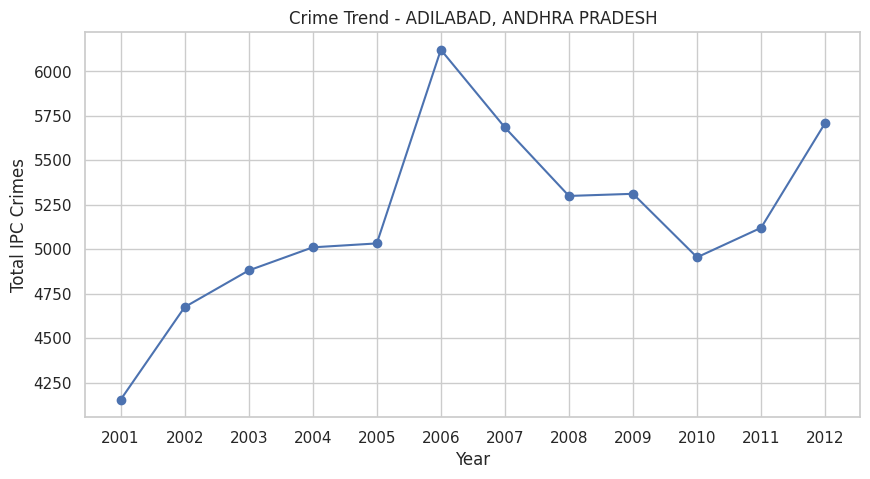

In [ ]:
complete_analysis(
    "ANDHRA PRADESH",
    "ADILABAD",
    2011
)